# Team 14: Road to 2030 (Portugal), appendix to the Executive Brief

This notebook is the technical appendix to the deck. Every number and every chart in the deck can be traced to a cell here, and every table and chart names its sources (S1–S4, as on the deck's sources slide 13 and in Appendix B of the Executive Brief).
Run the cells top to bottom from this folder with Python 3 (pandas, SciPy, matplotlib). The raw files are already in `data/raw/`; the download steps (scripts 01 and 06) only need to run once and are not repeated here.

## Sources

The four sources of the deck (slide 13). The short name in brackets is the one used in the source lines of the slides and below.

| ID | Dataset (short name) | Publisher | Used for | Website |
|---|---|---|---|---|
| **S1** | World Cup matches and squad lists, 2006–2026 (*FIFA API*) | FIFA | Results incl. extra time and shoot-outs, rounds reached, group places, player positions | api.fifa.com (matches: `api/v3/calendar/matches?idCompetition=17`; squads: `api/v3/live/football`) |
| **S2** | FIFA World Cup 2026, 48 teams dataset (*Kaggle WC 2026*) | Khayal Mammadov (Kaggle), values from Transfermarkt | Squad market values 2026 | kaggle.com/datasets/khayalmammadov/fifa-world-cup-2026-48-teams-dataset |
| **S3** | transfermarkt-datasets, player market values (*transfermarkt-datasets*) | David Cariboo (dcaribou), values from Transfermarkt | Player values by position, 2010–2026 | github.com/dcaribou/transfermarkt-datasets |
| **S4** | Squad market values 2006–2022 in published studies (*Squad value studies 2006–22*) | 2006 Baur & Lehmann, TCD IIIS DP 217 (published after the tournament) · 2010 Gerhards & Wagner, FU Berlin Research Note 36 · 2014 ING Cuponomics · 2018 DIW aktuell 12 · 2022 Planet Football; all Transfermarkt values | Squad market values before 2026 | tcd.ie · fu-berlin.de · think.ing.com · diw.de · planetfootball.com |

Full URLs are in `scripts/01_fetch.py` (S1 matches, S4), `scripts/06_fetch_squads.py` (S1 squads), `scripts/02_squad_values.py` (S2, S4) and `scripts/07_player_values.py` (S3).
All derived tables come from the team's scripts in `scripts/`; they are the method, not a source.

*Check data, not a source of any deck number:* Kaggle mann14, "2026 FIFA World Cup" (kaggle.com/datasets/mann14/2026-fifa-world-cup). It is only used for the data-cleaning checks in section 3 (deck slide 28).

## 1. Rebuild the clean tables from the raw files

Runs the team's scripts 02–04 and 07 on the raw files. If one of them fails, its error is printed.

In [1]:
import subprocess, sys
for s in ['02_squad_values', '03_build_tables', '04_analysis', '07_player_values']:
    r = subprocess.run([sys.executable, '-I', f'scripts/{s}.py'], capture_output=True, text=True)
    print(s, 'ok' if r.returncode == 0 else r.stderr)

02_squad_values ok
03_build_tables ok
04_analysis ok


07_player_values ok


## 2. The data

One row per squad (`teams`), match (`matches`), player (`players`) and squad split by line (`squads`). The table shows Portugal at each World Cup.

In [2]:
import pandas as pd
teams = pd.read_csv('data/clean/teams.csv'); teams = teams[teams.year >= 2006]
matches = pd.read_csv('data/clean/matches.csv'); matches = matches[matches.year >= 2006]
players = pd.read_csv('data/clean/players.csv')
squads = pd.read_csv('data/clean/squad_positions.csv')
print(len(teams), 'squads |', len(matches), 'matches |', len(players), 'players')
teams[teams.code == 'POR'][['year','value_m','value_rank','stage']]

208 squads | 424 matches | 4972 players


,year,value_m,value_rank,stage
332,2006,234.0,6.0,Semi-final
374,2010,292.1,8.0,Round of 16
423,2014,322.0,9.0,Group stage
439,2018,464.5,8.0,Round of 16
464,2022,937.0,4.0,Quarter-final
503,2026,980.0,5.0,Round of 16


Sources: S1 FIFA API, S2 Kaggle WC 2026, S4 Squad value studies 2006–22

## 3. Data cleaning checks

The three source errors of deck slide 28, plus the player-value coverage of slide 17. Each check prints what it found and then asserts it, so the notebook stops if the data ever changes.

### 3.1 Stage reached comes from the match list, not from a label

The mann14 check file labels South Africa as out in the group stage, but its own match list shows South Africa losing 1–0 to Canada in the Round of 32. So we derive each team's furthest round from the matches. Only then do the team counts per round fit the 48-team format: 48/32/16/8/4/2/1.

In [3]:
mt = pd.read_csv('data/raw/mann14/teams.csv')
mm = pd.read_csv('data/raw/mann14/matches.csv')
print('Label (eliminated_round) for South Africa:', mt.set_index('team').loc['South Africa', 'eliminated_round'])
print(mm[(mm.stage == 'Round of 32') & mm[['team_1', 'team_2']].eq('South Africa').any(axis=1)]
      [['stage', 'team_1', 'team_2', 'score_1', 'score_2', 'winner']].to_string(index=False))

ROUNDS = ['Group Stage', 'Round of 32', 'Round of 16', 'Quarterfinal', 'Semifinal', 'Final']
reached = {t: 0 for t in mt.team}
for r in mm[mm.stage.isin(ROUNDS)].itertuples():  # third-place match is not a round
    for t in (r.team_1, r.team_2):
        reached[t] = max(reached[t], ROUNDS.index(r.stage))
reached[mm[mm.stage == 'Final'].winner.iloc[0]] = 6  # champion
from_matches = [sum(v >= i for v in reached.values()) for i in range(7)]
from_label = (mt.eliminated_round != 'Group Stage').sum()
print('Teams reaching each round, derived from matches:', from_matches)
print('Teams beyond the group stage according to the label:', from_label)
assert from_matches == [48, 32, 16, 8, 4, 2, 1]
assert from_label == 31 and reached['South Africa'] == 1
# Cross-check against the FIFA API (S1), which the deck uses for all results
assert teams.query('year == 2026 and code == "RSA"').stage.item() == 'Round of 32'
print('OK: stage derived from matches; South Africa = Round of 32 in both the mann14 matches and S1')

Label (eliminated_round) for South Africa: Group Stage
      stage team_1       team_2  score_1  score_2 winner
Round of 32 Canada South Africa        1        0 Canada
Teams reaching each round, derived from matches: [48, 32, 16, 8, 4, 2, 1]
Teams beyond the group stage according to the label: 31
OK: stage derived from matches; South Africa = Round of 32 in both the mann14 matches and S1


Sources: Kaggle mann14 (check data); S1 FIFA API for the cross-check

### 3.2 Bookmaker title probabilities add up to more than 100%

The khayalmammadov file (S2) gives each team's title chance from bookmakers. They add up to 142.9% because bookmakers build in a margin, so we scale them to 100% before using them.

In [4]:
k = pd.read_csv('data/raw/khayalmammadov/World Cup 2026.csv', encoding='utf-8-sig')
p_raw = k['Championship Prob. (%)']
p_scaled = p_raw / p_raw.sum() * 100
spain = k.Team.eq('Spain')
print(f'Sum of title probabilities: {p_raw.sum():.1f}%  -> after scaling: {p_scaled.sum():.1f}%')
print(f'Spain: {p_raw[spain].item():.1f}% before scaling, {p_scaled[spain].item():.1f}% after')
assert round(p_raw.sum(), 1) == 142.9 and round(p_scaled.sum(), 6) == 100

Sum of title probabilities: 142.9%  -> after scaling: 100.0%
Spain: 20.0% before scaling, 14.0% after


Sources: S2 Kaggle WC 2026

### 3.3 One team name needs fixing before the join

S2 writes "Bosnia & Herz.", the mann14 check file writes "Bosnia and Herzegovina". Joined on the raw names, Bosnia drops out of the matched teams; with the one-line fix, all 48 teams match 1:1. (The history pipeline maps both spellings to the FIFA code BIH in `scripts/02_squad_values.py`.)

In [5]:
def join(names):
    return pd.DataFrame({'team': names}).merge(mt[['team']], on='team', how='outer', indicator=True)

before = join(k.Team)
print('Without fix:', (before._merge == 'both').sum(), 'teams matched; unmatched:',
      before[before._merge != 'both'].team.tolist())
fixed = k.Team.replace({'Bosnia & Herz.': 'Bosnia and Herzegovina'})
after = join(fixed)
pd.DataFrame({'team': fixed}).merge(mt[['team']], on='team', validate='1:1')  # raises if not 1:1
print('With fix:   ', (after._merge == 'both').sum(), 'teams matched,', (after._merge != 'both').sum(), 'unmatched')
assert (before._merge == 'both').sum() == 47
assert len(after) == 48 and (after._merge == 'both').all()

Without fix: 47 teams matched; unmatched: ['Bosnia & Herz.', 'Bosnia and Herzegovina']
With fix:    48 teams matched, 0 unmatched


Sources: S2 Kaggle WC 2026; Kaggle mann14 (check data)

### 3.4 How much of each squad's value we can trace to players (slide 17)

We match each player in the FIFA squad lists (S1) to his Transfermarkt value history (S3) and compare the sum with the published squad value (S2, S4). Before 2010 only about half the value of the top-10 squads can be traced, so the position analysis starts in 2010.

In [6]:
cov = squads.groupby('year').agg(players=('players', 'sum'), with_value=('valued', 'sum'),
                                 median_all=('coverage', 'median'))
cov['median_top10'] = squads[squads.value_rank <= 10].groupby('year').coverage.median()
print(cov.to_string(formatters={'median_all': '{:.0%}'.format, 'median_top10': '{:.0%}'.format}))
assert cov.loc[2006, 'median_top10'] < 0.6 and (cov.loc[2010:, 'median_top10'] >= 0.8).all()

      players  with_value median_all median_top10
year                                             
2006      722         182        32%          49%
2010      724         410        64%          81%
2014      728         557        84%          90%
2018      730         594        96%          99%
2022      827         719        97%          98%
2026     1241        1005        64%          91%


Sources: S1 FIFA API, S2 Kaggle WC 2026, S3 transfermarkt-datasets, S4 Squad value studies 2006–22 (coverage = sum of traced player values ÷ published squad value)

## 4. All slide numbers

Runs `scripts/08_story_numbers.py` and prints the result, which is the same as `data/clean/story_numbers.txt`. The tables it builds (`s8`) feed the charts and checks below, so they use exactly the deck's definitions.

In [7]:
import runpy, io, contextlib
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    s8 = runpy.run_path('scripts/08_story_numbers.py')
print(buf.getvalue())
T, P, M = s8['teams'], s8['p'], s8['matches']   # squads with band and group place; squads by line 2010+ with line ranks; matches 2006+
TOP = P[P.value_rank <= 10]    # the 50 top-10 squads 2010-2026 (same as s8['top'], plus whole-squad rank tot_r)

A. DATA
World Cups 2006-2026: 6, squads 208, matches 424, knockout matches 112
Players in FIFA squads: 4972; matched to Transfermarkt 3634, with a value 3467
Median squad value per World Cup (€m): 2006 66, 2010 102, 2014 142, 2018 208, 2022 266, 2026 415
Player values traced, as share of published squad value (median of the top-10 squads): 2006 49%, 2010 81%, 2014 90%, 2018 99%, 2022 98%, 2026 91%
Median over all squads: 2006 32%, 2010 64%, 2014 84%, 2018 96%, 2022 97%, 2026 64%

B. WHAT A TOP-10 SQUAD IS (2026)
  #1  France       €1,580m  Semi-final
  #2  England      €1,250m  Semi-final
  #2  Spain        €1,250m  Champion
  #4  Brazil       €1,100m  Round of 16
  #5  Argentina    €980m  Final
  #5  Germany      €980m  Round of 32
  #5  Portugal     €980m  Round of 16
  #8  Netherlands  €870m  Round of 32
  #9  Belgium      €680m  Quarter-final
  #10  Colombia     €660m  Round of 16
  #11  Mexico       €650m  Round of 16
  #11  Norway       €650m  Quarter-final
  Median of 48 squads:

Sources: S1 FIFA API, S2 Kaggle WC 2026, S3 transfermarkt-datasets, S4 Squad value studies 2006–22 (sections A–D, F, G use S1, S2, S4; section E also S3)

## 5. The charts of the main story (slides 3–10)

Simple versions of the deck charts (slides 3, 4, 5, 6, 8, 9, 10), drawn from the tables above, with the slide's chart title. Portugal is highlighted in red. Each cell asserts that the plotted values are the ones printed on the slide.

In [8]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RED, GREY, BLUE = '#c8102e', '#b0b0b0', '#1f4e79'

SOURCES = {'S1': 'FIFA API', 'S2': 'Kaggle WC 2026', 'S3': 'transfermarkt-datasets', 'S4': 'Squad value studies 2006–22'}

def source(fig, ids):
    text = ', '.join(f'{i} {SOURCES[i]}' for i in ids.split())
    fig.text(0.01, -0.04, 'Sources: ' + text, fontsize=8, color='grey', ha='left')

def bar_labels(ax, bars, labels):
    for b, s in zip(bars, labels):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), s, ha='center', va='bottom', fontsize=8)

Matplotlib is building the font cache; this may take a moment.


**Slide 3.** The 10 most valuable squads at the 2026 World Cup, pre-tournament squad market value, against the median of all 48 squads.

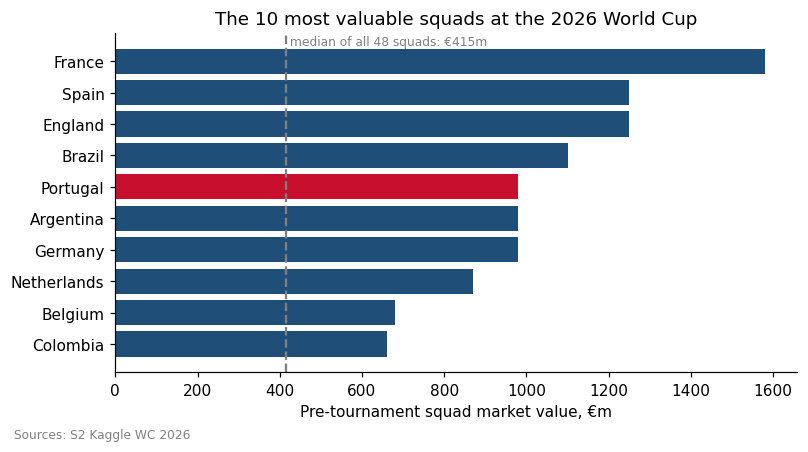

In [9]:
# order as on the slide: by value; ties (€1,250m, €980m) with Portugal first, then by FIFA ranking
ORDER = ['France', 'Spain', 'England', 'Brazil', 'Portugal', 'Argentina', 'Germany', 'Netherlands', 'Belgium', 'Colombia']
t26 = T[T.year == 2026].set_index('team').loc[ORDER].reset_index()
med = T[T.year == 2026].value_m.median()
assert set(ORDER) == set(T[(T.year == 2026) & (T.value_rank <= 10)].team)   # exactly the top 10 by value
assert t26.value_m.tolist() == [1580, 1250, 1250, 1100, 980, 980, 980, 870, 680, 660] and med == 415
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(t26.team[::-1], t26.value_m[::-1], color=[RED if c == 'POR' else BLUE for c in t26.code[::-1]])
ax.axvline(med, color='grey', ls='--'); ax.text(med, 9.5, f' median of all 48 squads: €{med:.0f}m', color='grey', fontsize=8)
ax.set_xlabel('Pre-tournament squad market value, €m'); ax.set_title('The 10 most valuable squads at the 2026 World Cup')
source(fig, 'S2'); plt.show()

**Slide 4.** World Cup finals reached by the seven nations that were in the top 10 by squad market value at all six World Cups, 2006–2026.

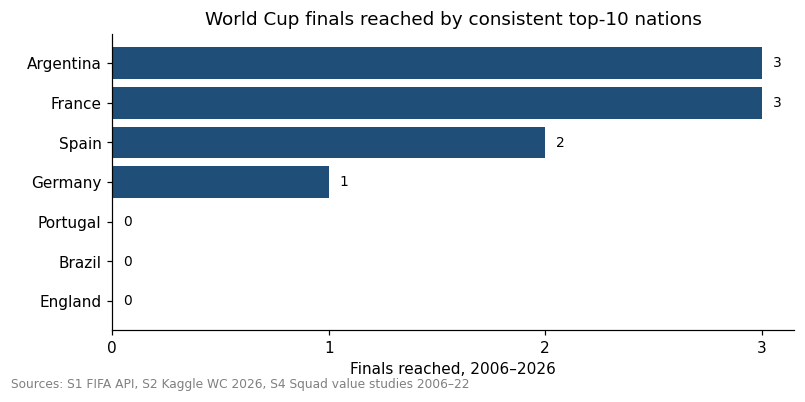

In [10]:
always = T[T.value_rank <= 10].groupby('code').year.nunique().loc[lambda s: s == 6].index
fin = T[T.code.isin(always)].groupby('team').stage_n.agg(lambda s: (s >= 6).sum())
fin = fin.loc[['England', 'Brazil', 'Portugal', 'Germany', 'Spain', 'France', 'Argentina']]  # slide order, bottom to top
assert fin.to_dict() == {'Argentina': 3, 'France': 3, 'Spain': 2, 'Germany': 1, 'Portugal': 0, 'Brazil': 0, 'England': 0}
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(fin.index, fin, color=[RED if t == 'Portugal' else BLUE for t in fin.index])
for b, v in zip(bars, fin):
    ax.text(v + 0.05, b.get_y() + b.get_height() / 2, str(v), va='center', fontsize=9)
ax.set_xticks(range(4)); ax.set_xlabel('Finals reached, 2006–2026')
ax.set_title('World Cup finals reached by consistent top-10 nations')
source(fig, 'S1 S2 S4'); plt.show()

**Slide 5.** Share of squads in each rank group (by squad market value before each World Cup) that reached the final, 2006–2026.

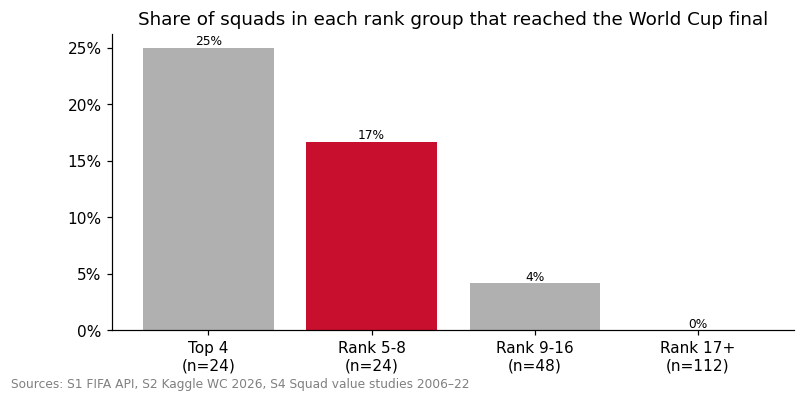

In [11]:
BANDS = ['Top 4', 'Rank 5-8', 'Rank 9-16', 'Rank 17+']
b = T.groupby('band').stage_n.agg(n='size', final=lambda s: (s >= 6).mean()).loc[BANDS]
assert [round(x * 100) for x in b.final] == [25, 17, 4, 0]
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar([f'{k}\n(n={n})' for k, n in b.n.items()], b.final, color=[GREY, RED, GREY, GREY])
bar_labels(ax, bars, [f'{v:.0%}' for v in b.final])
ax.yaxis.set_major_formatter('{x:.0%}')
ax.set_title('Share of squads in each rank group that reached the World Cup final')
source(fig, 'S1 S2 S4'); plt.show()

Rank 5–8 is highlighted because Portugal was in that group at four of six World Cups.

**Slide 6.** Share of top-10 squads (by total squad value) that reached the final, by whether each position group was top 5 by market value in its World Cup, 2010–2026.

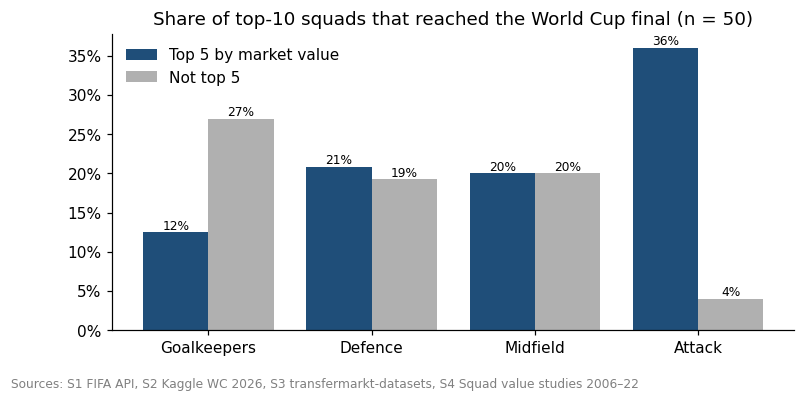

In [12]:
NAMES = {'GK': 'Goalkeepers', 'DF': 'Defence', 'MF': 'Midfield', 'FW': 'Attack'}
yes = [(TOP[TOP[k + '_r'] <= 5].stage_n >= 6).mean() for k in NAMES]
no = [(TOP[TOP[k + '_r'] > 5].stage_n >= 6).mean() for k in NAMES]
assert [round(x * 100) for x in yes] == [12, 21, 20, 36] and [round(x * 100) for x in no] == [27, 19, 20, 4]
fig, ax = plt.subplots(figsize=(8, 3.5))
x = range(len(NAMES))
b1 = ax.bar([i - 0.2 for i in x], yes, 0.4, color=BLUE, label='Top 5 by market value')
b2 = ax.bar([i + 0.2 for i in x], no, 0.4, color=GREY, label='Not top 5')
bar_labels(ax, b1, [f'{v:.0%}' for v in yes]); bar_labels(ax, b2, [f'{v:.0%}' for v in no])
ax.set_xticks(list(x), NAMES.values()); ax.yaxis.set_major_formatter('{x:.0%}'); ax.legend(frameon=False)
ax.set_title('Share of top-10 squads that reached the World Cup final (n = 50)')
source(fig, 'S1 S2 S3 S4'); plt.show()

**Slide 8.** Attackers' share of Portugal's squad market value, 2010–2026. Brackets: the value rank of Portugal's attack at that World Cup.

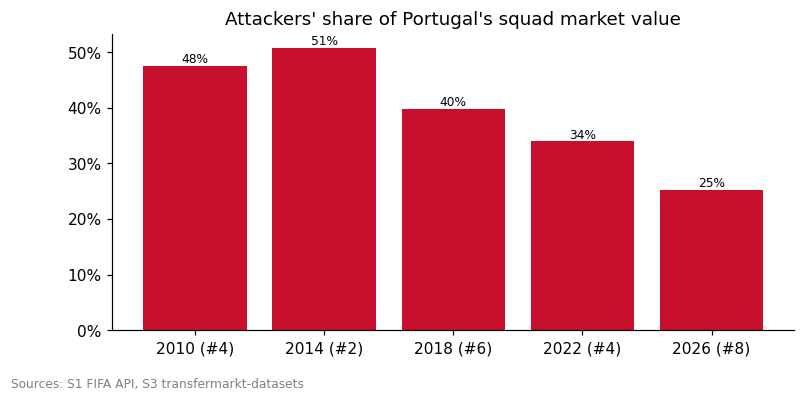

In [13]:
por8 = P[P.code == 'POR'].set_index('year')
share = por8.FW_m / por8.sum_m
assert [round(x * 100) for x in share] == [48, 51, 40, 34, 25] and por8.FW_r.astype(int).tolist() == [4, 2, 6, 4, 8]
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar([f'{y} (#{r:.0f})' for y, r in por8.FW_r.items()], share, color=RED)
bar_labels(ax, bars, [f'{v:.0%}' for v in share])
ax.yaxis.set_major_formatter('{x:.0%}')
ax.set_title("Attackers' share of Portugal's squad market value")
source(fig, 'S1 S3'); plt.show()

Share = value of Portugal's forwards ÷ sum of all traced player values of the squad (`FW_m / sum_m`, as in `08_story_numbers.py`).

**Slide 9.** Share of the top-8 squads by market value that reached the quarter-finals, by group finish, 2006–2026.

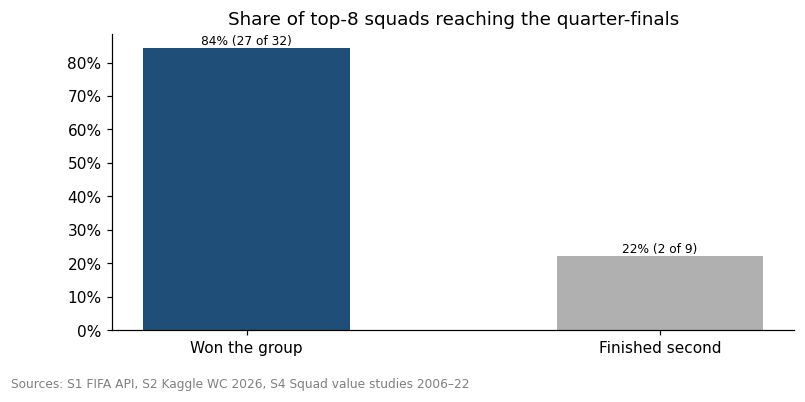

In [14]:
t8 = T[T.value_rank <= 8]
g = t8[t8.group_place.isin([1, 2])].groupby('group_place').stage_n.agg(qf=lambda s: (s >= 4).sum(), n='size')
assert (g.loc[1, 'qf'], g.loc[1, 'n'], g.loc[2, 'qf'], g.loc[2, 'n']) == (27, 32, 2, 9)
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(['Won the group', 'Finished second'], g.qf / g.n, color=[BLUE, GREY], width=0.5)
bar_labels(ax, bars, [f'{q / n:.0%} ({q} of {n})' for q, n in zip(g.qf, g.n)])
ax.yaxis.set_major_formatter('{x:.0%}')
ax.set_title('Share of top-8 squads reaching the quarter-finals')
source(fig, 'S1 S2 S4'); plt.show()

**Slide 10.** Share of knockout matches won by the higher-value squad, by how the match was decided, 2006–2026. Includes the third-place matches; a shoot-out counts for the side that went through.

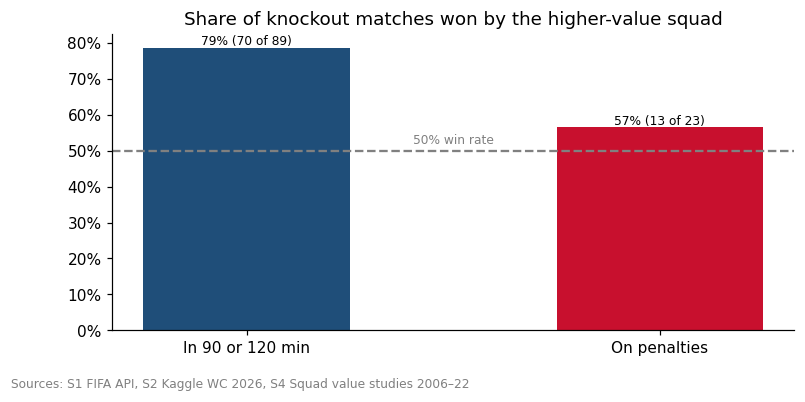

In [15]:
ko = M[(M.phase != 'Group') & M.richer.notna()]
won = ko.groupby('shootout').richer_won.agg(['sum', 'size'])
assert (won.loc[0, 'sum'], won.loc[0, 'size'], won.loc[1, 'sum'], won.loc[1, 'size']) == (70, 89, 13, 23)
rate = won['sum'] / won['size']
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(['In 90 or 120 min', 'On penalties'], rate, color=[BLUE, RED], width=0.5)
bar_labels(ax, bars, [f'{r:.0%} ({s:.0f} of {n})' for r, s, n in zip(rate, won['sum'], won['size'])])
ax.axhline(0.5, color='grey', ls='--'); ax.text(0.5, 0.52, '50% win rate', color='grey', fontsize=8, ha='center')
ax.yaxis.set_major_formatter('{x:.0%}')
ax.set_title('Share of knockout matches won by the higher-value squad')
source(fig, 'S1 S2 S4'); plt.show()

## 6. Top-10 squads 2010–2026: attack and group place (backup slide 21)

Of the 50 squads that were in their World Cup's top 10 by value (2010–2026), how many reached the final, split by whether the squad had a top-5 attack (by forwards' value) and whether it won its group. Slide 21 shows the related split by overall rank (1–5 vs 6–10) and attack rank; those numbers are in section 4, part E ("Control for total value").

In [16]:
top = TOP.merge(T[['year', 'code', 'group_place']], on=['year', 'code'])
top['top5_attack'] = (top.FW_r <= 5).map({True: 'yes', False: 'no'})
top['group_winner'] = (top.group_place == 1).map({True: 'yes', False: 'no'})
tab = (top.groupby(['top5_attack', 'group_winner']).stage_n
          .agg(lambda s: f'{(s >= 6).sum()}/{len(s)}').unstack().loc[['yes', 'no'], ['yes', 'no']])
tab.index.name, tab.columns.name = 'top-5 attack', 'group winner'
print('Reached the final / squads in the cell\n'); print(tab.to_string())
finalists = (top.stage_n >= 6).sum()
print(f'\nAll finalists among the top-10 squads: {finalists}; in the yes/yes cell: {tab.loc["yes", "yes"]}')
assert len(top) == 50 and tab.loc['yes', 'yes'] == '9/19'

Reached the final / squads in the cell

group winner   yes    no
top-5 attack            
yes           9/19   0/6
no            1/12  0/13

All finalists among the top-10 squads: 10; in the yes/yes cell: 9/19


Sources: S1 FIFA API, S2 Kaggle WC 2026, S3 transfermarkt-datasets, S4 Squad value studies 2006–22

## 7. Backup slide 22: which line's value goes with going further?

Spearman rank correlation between each line's value rank in its World Cup and the round reached, for the 50 top-10 squads 2010–2026. Positive means: the more valuable that line, the further the team went. "Whole squad" ranks the sum of all traced player values, as in `08_story_numbers.py`; the published-value rank is shown for comparison. No script computed these before; this cell is their source.

In [17]:
from scipy.stats import spearmanr
rank_cols = {'Goalkeepers': 'GK_r', 'Defence': 'DF_r', 'Midfield': 'MF_r', 'Attack': 'FW_r',
             'Whole squad': 'tot_r', 'Whole squad (published value rank)': 'value_rank'}
res = pd.DataFrame([(k, *spearmanr(-TOP[c], TOP.stage_n)) for k, c in rank_cols.items()],
                   columns=['line', 'rho', 'p']).set_index('line')
deck = {'Attack': 0.37, 'Whole squad': 0.35, 'Defence': 0.17, 'Midfield': 0.16, 'Goalkeepers': 0.03}
res['deck'] = pd.Series(deck)
print(f'n = {len(TOP)}\n'); print(res.to_string(formatters={'rho': '{:.3f}'.format, 'p': '{:.4f}'.format}))
assert len(TOP) == 50
assert all(round(res.rho[k], 2) == v for k, v in deck.items())
assert round(res.p['Attack'], 3) == 0.008 and round(res.p['Whole squad'], 2) == 0.01

n = 50

                                     rho      p  deck
line                                                 
Goalkeepers                        0.029 0.8390  0.03
Defence                            0.175 0.2250  0.17
Midfield                           0.156 0.2784  0.16
Attack                             0.372 0.0079  0.37
Whole squad                        0.354 0.0117  0.35
Whole squad (published value rank) 0.333 0.0183   NaN


Sources: S1 FIFA API, S2 Kaggle WC 2026, S3 transfermarkt-datasets, S4 Squad value studies 2006–22

## 8. Was Portugal unlucky never to reach a final? (not on a slide; for Q&A)

For each World Cup we take Portugal's value rank, look up how often squads in that rank band reached the final (2006–2026, section 4 D), and multiply the chances of *not* reaching it. The result is the chance of zero finals in six attempts if Portugal had done exactly as well as its value band.

In [18]:
por = T[T.code == 'POR'][['year', 'value_rank', 'band']].copy()
por['p_final'] = por.band.map(lambda b: s8['rates'][b][0])
por['p_final_rounded'] = por.p_final.round(2)   # the rates as shown on the slide (25%, 17%, 4%)
print(por.to_string(index=False, formatters={'p_final': '{:.3f}'.format}))
p0 = (1 - por.p_final).prod(); p0r = (1 - por.p_final_rounded).prod()
print(f'\nP(no final in 6 World Cups): {p0:.1%} with exact band rates, {p0r:.1%} with rates rounded to whole percent')
assert 0.33 < p0 < 0.36

 year  value_rank      band p_final  p_final_rounded
 2006         6.0  Rank 5-8   0.167             0.17
 2010         8.0  Rank 5-8   0.167             0.17
 2014         9.0 Rank 9-16   0.042             0.04
 2018         8.0  Rank 5-8   0.167             0.17
 2022         4.0     Top 4   0.250             0.25
 2026         5.0  Rank 5-8   0.167             0.17

P(no final in 6 World Cups): 34.7% with exact band rates, 34.2% with rates rounded to whole percent


Sources: S1 FIFA API, S2 Kaggle WC 2026, S4 Squad value studies 2006–22

## 9. Backup slide 23: Portugal by position group

Value rank of each Portugal position group within its World Cup, and its value in € million, 2010–2026 (same as section 4, part E).

In [19]:
POS = {'GK': 'Goalkeepers', 'DF': 'Defence', 'MF': 'Midfield', 'FW': 'Attack'}
por23 = P[P.code == 'POR'].set_index('year')
tab23 = pd.DataFrame({POS[k]: [f'#{r:.0f} · €{v:.0f}m' for r, v in zip(por23[k + '_r'], por23[k + '_m'])]
                      for k in POS}, index=por23.index).T
print(tab23.to_string())
assert tab23.loc['Defence', 2026] == '#2 · €289m' and tab23.loc['Attack'].tolist() == [
    '#4 · €118m', '#2 · €149m', '#6 · €197m', '#4 · €298m', '#8 · €254m']

year               2010        2014         2018        2022        2026
Goalkeepers   #6 · €13m   #6 · €28m    #7 · €37m   #5 · €58m   #6 · €50m
Defence       #7 · €61m  #10 · €56m    #8 · €94m  #3 · €270m  #2 · €289m
Midfield      #9 · €55m  #13 · €62m  #10 · €167m  #5 · €251m  #3 · €412m
Attack       #4 · €118m  #2 · €149m   #6 · €197m  #4 · €298m  #8 · €254m


Sources: S1 FIFA API, S3 transfermarkt-datasets

## 10. Other numbers in the deck (slides 11, 20, 24, 25)

Numbers on these slides that `08_story_numbers.py` does not print. Each cell recomputes them from the clean tables and asserts the value on the slide.

**Slide 11.** Baseline for the target "finish first in the group": Portugal's group place and the round it reached at each World Cup (group place from points, goal difference and goals).

In [20]:
por_g = T[T.code == 'POR'].set_index('year')[['group_place', 'stage', 'stage_n']]
print(por_g[['group_place', 'stage']].to_string())
assert por_g.group_place.astype(int).tolist() == [1, 2, 3, 2, 1, 2]
assert (por_g[por_g.group_place == 1].stage_n >= 4).all()    # won the group: quarter-final or further (2006, 2022)
assert (por_g[por_g.group_place == 2].stage_n < 4).all()     # finished second: out before the quarter-final (2010, 2018, 2026)

      group_place          stage
year                            
2006            1     Semi-final
2010            2    Round of 16
2014            3    Group stage
2018            2    Round of 16
2022            1  Quarter-final
2026            2    Round of 16


Sources: S1 FIFA API

The other two targets on slide 11 (two competitive starts each for two emerging forwards; two full shoot-out rehearsals with different line-ups in the final camp) are targets, not data.

**Backup slide 20.** How Portugal went out at each World Cup: opponent, score, the opponent's value rank and whether it was the more or less valuable squad.

In [21]:
rows = []
for y in sorted(T[T.code == 'POR'].year):
    me = T[(T.year == y) & (T.code == 'POR')].iloc[0]
    lost = M[(M.year == y) & ~M.phase.isin(['Group', 'Third place']) & M[['team_1', 'team_2']].eq('POR').any(axis=1)
             & (M.winner != 'POR')]
    for r in lost.itertuples():
        opp = r.team_2 if r.team_1 == 'POR' else r.team_1
        o = T[(T.year == y) & (T.code == opp)].iloc[0]
        score = f'{r.score_1}–{r.score_2}' if r.team_1 == 'POR' else f'{r.score_2}–{r.score_1}'
        rows.append((y, r.phase, o.team, score, f'#{o.value_rank:.0f} · €{o.value_m:,.0f}m',
                     'richer' if o.value_m > me.value_m else 'cheaper'))
    if lost.empty:
        rows.append((y, f'{me.stage} (group place {me.group_place:.0f})', '', '', '', ''))
exits = pd.DataFrame(rows, columns=['year', 'round', 'lost to', 'score', 'opponent rank · value', 'relative value'])
print(exits.to_string(index=False))
assert exits['relative value'].tolist() == ['richer', 'richer', '', 'cheaper', 'cheaper', 'richer']
assert exits['lost to'].tolist() == ['France', 'Spain', '', 'Uruguay', 'Morocco', 'Spain']

 year                       round lost to score opponent rank · value relative value
 2006                  Semi-final  France   0–1            #5 · €270m         richer
 2010                 Round of 16   Spain   0–1            #1 · €650m         richer
 2014 Group stage (group place 3)                                                   
 2018                 Round of 16 Uruguay   1–2            #9 · €372m        cheaper
 2022               Quarter-final Morocco   0–1           #18 · €251m        cheaper
 2026                 Round of 16   Spain   0–1          #2 · €1,250m         richer


Sources: S1 FIFA API, S2 Kaggle WC 2026, S4 Squad value studies 2006–22

**Backup slide 24.** Quarter-finalists ranked 13th or lower by squad value, and whether they won a shoot-out on the way.

In [22]:
q = T[(T.stage_n >= 4) & (T.value_rank >= 13)].sort_values(['value_rank', 'year'], ascending=[False, True])
q = q.assign(won_shootout=q.shootout_wins.gt(0).map({True: 'yes', False: 'no'}))
print(q[['year', 'team', 'value_rank', 'stage', 'won_shootout']].to_string(index=False))
assert len(q) == 10 and (q.won_shootout == 'yes').sum() == 8

 year        team  value_rank         stage won_shootout
 2014  Costa Rica        29.0 Quarter-final          yes
 2018      Sweden        22.0 Quarter-final           no
 2010    Paraguay        21.0 Quarter-final          yes
 2026 Switzerland        19.0 Quarter-final          yes
 2018      Russia        18.0 Quarter-final          yes
 2022     Morocco        18.0    Semi-final          yes
 2010       Ghana        16.0 Quarter-final           no
 2006     Ukraine        15.0 Quarter-final          yes
 2010     Uruguay        13.0    Semi-final          yes
 2026     Morocco        13.0 Quarter-final          yes


Sources: S1 FIFA API, S2 Kaggle WC 2026, S4 Squad value studies 2006–22

**Backup slide 25.** Ronaldo's share of Portugal's squad value: his value ÷ the sum of the squad's matched player values, and his rank among Portugal's players by value ("of" = squad size).

In [23]:
rows = []
for y, g in players[players.code == 'POR'].groupby('year'):
    v = g.dropna(subset=['value_m']).sort_values('value_m', ascending=False).reset_index(drop=True)
    r = v[v.tm_name.fillna('').str.contains('Cristiano Ronaldo')]
    rows.append((y, r.value_m.item() / v.value_m.sum(), r.value_m.item(), f'#{r.index[0] + 1} of {len(g)}'))
cr = pd.DataFrame(rows, columns=['year', 'share', 'value_m', 'rank'])
print(cr.to_string(index=False, formatters={'share': '{:.0%}'.format, 'value_m': '€{:.0f}m'.format}))
assert [round(x * 100) for x in cr.share] == [25, 30, 34, 20, 2, 1]
assert cr['rank'].tolist() == ['#1 of 22', '#1 of 23', '#1 of 23', '#1 of 23', '#16 of 25', '#21 of 26']

 year share value_m      rank
 2006   25%    €26m  #1 of 22
 2010   30%    €75m  #1 of 23
 2014   34%   €100m  #1 of 23
 2018   20%   €100m  #1 of 23
 2022    2%    €20m #16 of 25
 2026    1%    €10m #21 of 26


Sources: S1 FIFA API, S2 Kaggle WC 2026, S3 transfermarkt-datasets, S4 Squad value studies 2006–22

## 11. Full results by World Cup, price band and shoot-out

Output of `scripts/04_analysis.py` (`data/clean/history_results.txt`).

In [24]:
txt = open('data/clean/history_results.txt').read()
print(txt)
# the medians match section 4, part A (and backup slide 18)
for y, m in [(2006, 66), (2010, 102), (2014, 142), (2018, 208), (2022, 266), (2026, 415)]:
    assert f'median €{m}m)' in txt.split(f'{y}  (')[1].split('\n')[0], y

1. WHO GOT HOW FAR, PER WORLD CUP (value rank 1 = most expensive squad)

2006  (32 teams, most expensive Italy €378m, median €66m)
  Champion       Italy (#1, €378m)
  Final          France (#5, €270m)
  Semi-final     Portugal (#6, €234m), Germany (#9, €180m)
  Quarter-final  Brazil (#2, €365m), England (#3, €341m), Argentina (#7, €228m), Ukraine (#15, €81m)

2010  (32 teams, most expensive Spain €650m, median €102m)
  Champion       Spain (#1, €650m)
  Final          Netherlands (#9, €271m)
  Semi-final     Germany (#7, €308m), Uruguay (#13, €137m)
  Quarter-final  Argentina (#3, €388m), Brazil (#6, €353m), Ghana (#16, €103m), Paraguay (#21, €80m)

2014  (32 teams, most expensive Spain €675m, median €142m)
  Champion       Germany (#2, €609m)
  Final          Argentina (#5, €410m)
  Semi-final     Brazil (#3, €507m), Netherlands (#11, €225m)
  Quarter-final  France (#4, €453m), Belgium (#6, €378m), Colombia (#11, €225m), Costa Rica (#29, €32m)

2018  (32 teams, most expensive France 

Sources: S1 FIFA API, S2 Kaggle WC 2026, S4 Squad value studies 2006–22